# 03: Training across datasets: what works and what doesn't

**Question:** if we train on some datasets, does the model work on a network it has never seen? CyberShield will always run on a network that isn't in its training data, so this is the test that matters.

**Five datasets**, all as Zeek `conn.log` records with timestamps:

| Dataset | Notes |
|---|---|
| CIC-IDS2017 | 5 days of office traffic; HuggingFace mirror, labelled from UNB's attack schedule |
| UNSW-NB15 | the creators' own Zeek logs, labelled from the official ground truth |
| UWF-2024 | UWF-ZeekData24 + Fall24-2 |
| UWF-2025 | UWF-ZeekDataSum25-1 + Sum25-2 (**same lab as UWF-2024**, so the two aren't fully independent) |
| AIT-LDSv2 | captures from the attacker's machine only: 96% attacks, so its FPR rests on few normal rows |

TON_IoT is left out: it has no timestamps, so windowing can't be tested, and our copy doesn't match the official file.

**Method**
- **Evaluation split:** inside each training dataset, 20% is held back for evaluation, split by 30-minute blocks of time (not random rows), so neighbouring connections of the same attack can't land on both sides.
- **Balance:** each dataset contributes at most 100,000 rows per class, so big datasets don't drown small ones.
- **Two feature sets:**
  - **Per-flow (14 features):** the connection's own Zeek fields (protocol, service, `conn_state`, duration, bytes, packets) plus 3 ratios.
  - **Windowed (19 features):** the same 14, plus 5 counts for the source host over the same 60 seconds: connections, distinct ports, share of failed connections, bytes sent, bytes received.
- **Model:** `HistGradientBoostingClassifier`, default settings, threshold 0.5.

**Metrics** (attack = positive class)

| Metric | Meaning | Good |
|---|---|---|
| **ROC-AUC** | how well the model's scores rank attacks above normal traffic, at any threshold | 1.0 (0.5 = guessing) |
| **F1** | balance of precision and recall at threshold 0.5 | 1.0 |
| **Recall** | share of attacks detected | 1.0 |
| **FPR** | false positive rate: share of normal traffic wrongly flagged | 0.0 |

F1 depends on the attack share of the test set. Most test sets here are 50% attacks; AIT-LDSv2 is 96%, which inflates its F1.

In [1]:
import itertools
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.metrics import f1_score, roc_auc_score

from cybershield.ml.train_zeek import fit_zeek_model
from cybershield.ml.zeek_features import (
    ZEEK_CAT_COLS, ZEEK_FLOW_RATIO_COLS, ZEEK_HOST_CTX_COLS, ZEEK_RAW_NUM_COLS,
    load_ait_zeek, load_cic2017_zeek, load_unsw_official_zeek, load_uwf_zeek,
)

warnings.filterwarnings("ignore", category=UserWarning)
SEED = 42
PER_FLOW = ZEEK_CAT_COLS + ZEEK_RAW_NUM_COLS + ZEEK_FLOW_RATIO_COLS
WINDOWED = PER_FLOW + ZEEK_HOST_CTX_COLS
FEATURE_SETS = {"Per-flow": PER_FLOW, "Windowed": WINDOWED}
METRICS = ["ROC-AUC", "F1", "Recall", "FPR"]
CAP_TRAIN, CAP_EVAL, CAP_TEST = 100_000, 30_000, 100_000


def cap(df, n):
    return pd.concat([g.sample(min(len(g), n), random_state=SEED) for _, g in df.groupby("label")])


def prepare(df):
    """Split one dataset into train / eval by 30-minute time blocks, and draw a test sample from all of it."""
    df = df[WINDOWED + ["label", "attack_type", "ts"]]
    block = (df.ts // 1800).astype("int64")
    eval_blocks = np.random.default_rng(SEED).choice(block.unique(), size=int(block.nunique() * 0.2), replace=False)
    is_eval = block.isin(eval_blocks)
    return {"train": cap(df[~is_eval], CAP_TRAIN), "eval": cap(df[is_eval], CAP_EVAL), "test": cap(df, CAP_TEST)}


DATA = {
    "CIC-IDS2017": prepare(load_cic2017_zeek()),
    "UNSW-NB15": prepare(load_unsw_official_zeek()),
    "UWF-2024": prepare(pd.concat([load_uwf_zeek("UWF-ZeekData24"), load_uwf_zeek("UWF-ZeekDataFall24-2")])),
    "UWF-2025": prepare(pd.concat([load_uwf_zeek("UWF-ZeekDataSum25-1"), load_uwf_zeek("UWF-ZeekDataSum25-2")])),
    "AIT-LDSv2": prepare(load_ait_zeek()),
}
NAMES = list(DATA)
pd.DataFrame({n: {part: f"{len(df):,} rows ({df.label.mean():.0%} attacks)" for part, df in d.items()} for n, d in DATA.items()}).T

,train,eval,test
CIC-IDS2017,"200,000 rows (50% attacks)","50,541 rows (41% attacks)","200,000 rows (50% attacks)"
UNSW-NB15,"149,440 rows (33% attacks)","44,301 rows (32% attacks)","163,741 rows (39% attacks)"
UWF-2024,"200,000 rows (50% attacks)","60,000 rows (50% attacks)","200,000 rows (50% attacks)"
UWF-2025,"200,000 rows (50% attacks)","60,000 rows (50% attacks)","200,000 rows (50% attacks)"
AIT-LDSv2,"103,172 rows (97% attacks)","4,775 rows (86% attacks)","103,858 rows (96% attacks)"


In [2]:
def metrics(y, score, threshold=0.5):
    """ROC-AUC from the raw scores; F1, recall and FPR from the decisions at `threshold`."""
    y, score = np.asarray(y), np.asarray(score)
    flagged = score >= threshold
    return {
        "ROC-AUC": roc_auc_score(y, score),
        "F1": f1_score(y, flagged),
        "Recall": flagged[y == 1].mean(),
        "FPR": flagged[y == 0].mean(),
    }


def evaluate(model, df, feats, threshold=0.5):
    return metrics(df.label, model.predict_proba(df[feats])[:, 1], threshold)


def show(df):
    return df.style.format("{:.3f}").background_gradient(cmap="Reds", subset=["FPR"], vmin=0, vmax=1)


def bars(ax, table, title, ylabel, colors=None):
    table.plot.bar(ax=ax, rot=0, width=0.8, color=colors)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_xlabel("")
    ax.set_ylim(0, 1.05)
    ax.grid(axis="y", alpha=0.3)
    ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=min(len(table.columns), 3), frameon=False)

## Experiment 1: Train on 4 datasets, test on the 5th

Each dataset takes a turn as the unseen test set; the model trains on the other four. Each model is scored twice:
- **Seen-data eval:** the 20% held back from the four training datasets.
- **Unseen dataset:** the fifth dataset.

In [3]:
rows = []
for held_out in NAMES:
    train_names = [n for n in NAMES if n != held_out]
    train = pd.concat([DATA[n]["train"] for n in train_names])
    seen_eval = pd.concat([DATA[n]["eval"] for n in train_names])
    for fs_name, feats in FEATURE_SETS.items():
        model = fit_zeek_model(train, feats)
        rows.append({"Unseen dataset": held_out, "Features": fs_name, "Tested on": "Seen-data eval", **evaluate(model, seen_eval, feats)})
        rows.append({"Unseen dataset": held_out, "Features": fs_name, "Tested on": "Unseen dataset", **evaluate(model, DATA[held_out]["test"], feats)})
exp1 = pd.DataFrame(rows)

print("Results on the unseen dataset:")
show(exp1[exp1["Tested on"] == "Unseen dataset"].set_index(["Unseen dataset", "Features"])[METRICS])

Results on the unseen dataset:


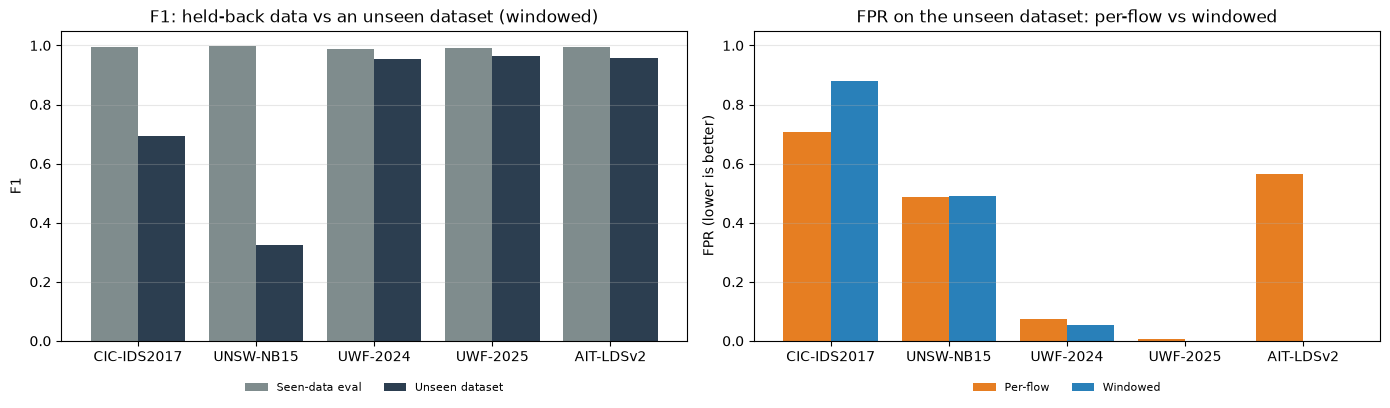

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
w = exp1[exp1.Features == "Windowed"].pivot(index="Unseen dataset", columns="Tested on", values="F1").loc[NAMES]
bars(axes[0], w[["Seen-data eval", "Unseen dataset"]], "F1: held-back data vs an unseen dataset (windowed)", "F1", ["#7f8c8d", "#2c3e50"])
fpr = exp1[exp1["Tested on"] == "Unseen dataset"].pivot(index="Unseen dataset", columns="Features", values="FPR").loc[NAMES]
bars(axes[1], fpr, "FPR on the unseen dataset: per-flow vs windowed", "FPR (lower is better)", ["#e67e22", "#2980b9"])
plt.tight_layout()
plt.show()

**What it shows**
- **The evaluation split is misleading.** On data held back from the training datasets, every model scores F1 ≈ 0.99 with FPR ≈ 0.01. On the unseen dataset, results drop sharply (left chart).
- **False positives are the main failure.** About half of UNSW-NB15's normal traffic is flagged, and most of CIC-IDS2017's (right chart). What the model learned as "normal" from four labs doesn't match a fifth lab's normal traffic.
- **UNSW-NB15 is worse than guessing.** Its ROC-AUC is 0.35–0.42, below 0.5: the model scores UNSW-NB15's normal traffic as *more* attack-like than its attacks. Its generated normal traffic looks like attacks to a model trained elsewhere.
- **The UWF results look good only because the other UWF release is in training** (same lab). Experiment 2 removes it.
- **Windowing** raises recall on every unseen dataset. Its effect on FPR is mixed: lower on UWF and AIT-LDSv2, higher on CIC-IDS2017.
- **ROC-AUC vs FPR:** on CIC-IDS2017 the windowed model's ROC-AUC is 0.91, yet its FPR is 0.88. The scores rank attacks above most normal traffic, but threshold 0.5 sits in the wrong place for that network.

## Experiment 2: Train on 3 datasets, test on 2

Every combination of two unseen datasets (10 in all). For each dataset, the results are averaged over the 4 combinations where it's unseen, and compared with experiment 1 (train on 4).

In [5]:
rows = []
for test_pair in itertools.combinations(NAMES, 2):
    train = pd.concat([DATA[n]["train"] for n in NAMES if n not in test_pair])
    for fs_name, feats in FEATURE_SETS.items():
        model = fit_zeek_model(train, feats)
        for n in test_pair:
            rows.append({"Pair": " + ".join(test_pair), "Unseen dataset": n, "Features": fs_name, **evaluate(model, DATA[n]["test"], feats)})
exp2 = pd.DataFrame(rows)

train3 = exp2.groupby(["Unseen dataset", "Features"])[METRICS].mean().assign(Training="Train on 3 (average)")
train4 = exp1[exp1["Tested on"] == "Unseen dataset"].set_index(["Unseen dataset", "Features"])[METRICS].assign(Training="Train on 4")
exp2_summary = pd.concat([train4, train3]).reset_index().set_index(["Unseen dataset", "Features", "Training"]).sort_index().loc[NAMES]
show(exp2_summary)

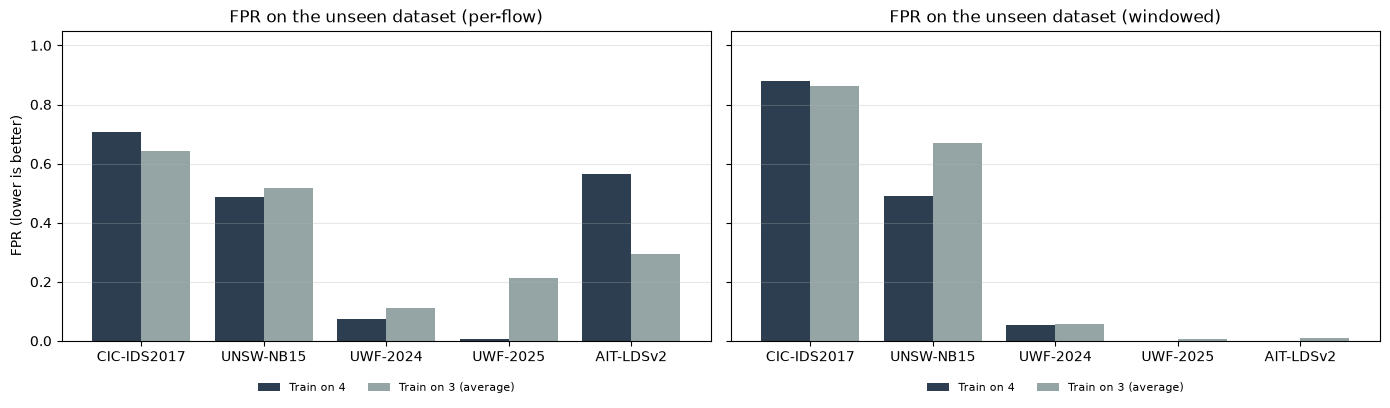

Both UWF releases unseen (trained on CIC-IDS2017, UNSW-NB15 and AIT-LDSv2 only):


,,ROC-AUC,F1,Recall,FPR
Unseen dataset,Features,,,,
UWF-2024,Per-flow,0.849,0.697,0.632,0.182
UWF-2025,Per-flow,0.693,0.553,0.693,0.815
UWF-2024,Windowed,0.893,0.805,0.724,0.073
UWF-2025,Windowed,0.935,0.887,0.800,0.005


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for ax, fs_name in zip(axes, FEATURE_SETS):
    t = exp2_summary.xs(fs_name, level="Features")["FPR"].unstack("Training").loc[NAMES]
    bars(ax, t[["Train on 4", "Train on 3 (average)"]], f"FPR on the unseen dataset ({fs_name.lower()})", "FPR (lower is better)", ["#2c3e50", "#95a5a6"])
plt.tight_layout()
plt.show()

print("Both UWF releases unseen (trained on CIC-IDS2017, UNSW-NB15 and AIT-LDSv2 only):")
show(exp2[exp2.Pair == "UWF-2024 + UWF-2025"].set_index(["Unseen dataset", "Features"])[METRICS])

**What it shows**
- **One fewer training dataset gives mixed results.** FPR rises on UNSW-NB15 and the UWF releases, but not on CIC-IDS2017 or AIT-LDSv2. *Which* datasets are in training matters more than how many, and neither closes the gap.
- **The UWF results confirm the same-lab effect.** With both UWF releases unseen, the per-flow model flags most of UWF-2025's normal traffic, against under 1% when UWF-2024 was in training.
- **The windowed model holds up better here:** it keeps UWF-2025's FPR low even without the other UWF release.

## Experiment 3: Train on 1 dataset, test on the other 4

Each dataset trains a model on its own; the model is then tested on its own 20% held-back blocks and on each of the other four datasets.

In [7]:
rows = []
for train_name in NAMES:
    for fs_name, feats in FEATURE_SETS.items():
        model = fit_zeek_model(DATA[train_name]["train"], feats)
        for test_name in NAMES:
            df = DATA[test_name]["eval" if test_name == train_name else "test"]
            rows.append({"Trained on": train_name, "Tested on": test_name, "Features": fs_name, **evaluate(model, df, feats)})
single = pd.DataFrame(rows)

print("Average over the 4 unseen datasets:")
unseen = single[single["Trained on"] != single["Tested on"]]
show(unseen.groupby(["Trained on", "Features"])[METRICS].mean().loc[NAMES])

Average over the 4 unseen datasets:


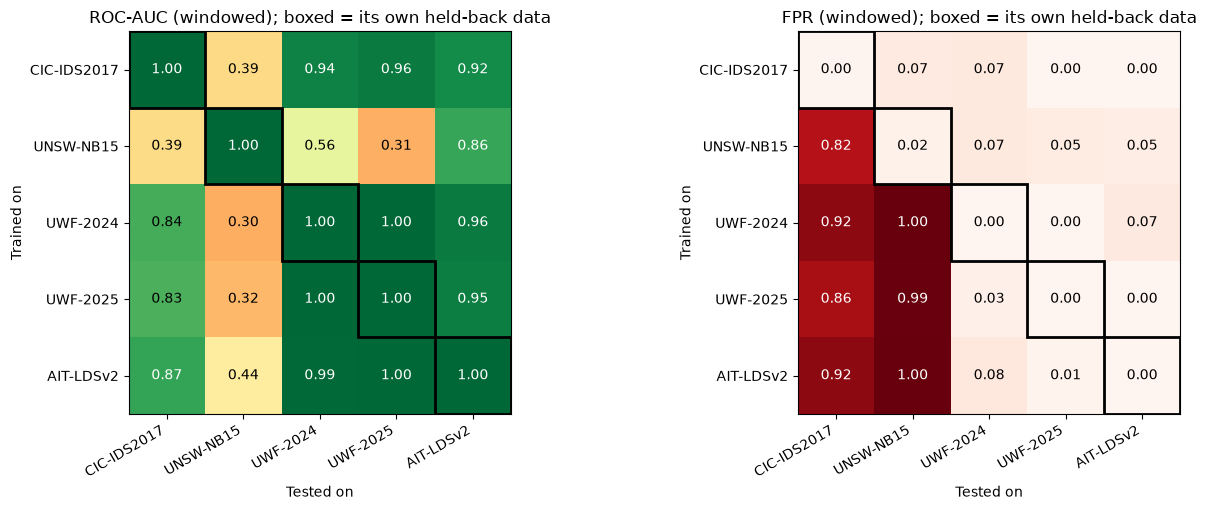

In [8]:
from matplotlib.patches import Rectangle

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
w = single[single.Features == "Windowed"]
for ax, metric, cmap, dark in [(axes[0], "ROC-AUC", "RdYlGn", lambda v: v < 0.2 or v > 0.85),
                               (axes[1], "FPR", "Reds", lambda v: v > 0.6)]:
    m = w.pivot(index="Trained on", columns="Tested on", values=metric).loc[NAMES, NAMES]
    ax.imshow(m, cmap=cmap, vmin=0, vmax=1)
    ax.set_xticks(range(len(NAMES)), NAMES, rotation=30, ha="right")
    ax.set_yticks(range(len(NAMES)), NAMES)
    ax.set_xlabel("Tested on")
    ax.set_ylabel("Trained on")
    for i in range(len(NAMES)):
        for j in range(len(NAMES)):
            v = m.iat[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if dark(v) else "black")
        ax.add_patch(Rectangle((i - 0.5, i - 0.5), 1, 1, fill=False, lw=2, ec="black"))
    ax.set_title(f"{metric} (windowed); boxed = its own held-back data")
plt.tight_layout()
plt.show()

**What it shows**
- **Every dataset looks perfect on its own held-back data** (boxed cells: ROC-AUC 1.00, FPR about 0). That says nothing about other networks.
- **False positives are again the main failure.** Models trained on UWF or AIT-LDSv2 flag 86–92% of CIC-IDS2017's normal traffic and almost all of UNSW-NB15's.
- **UNSW-NB15 doesn't fit with anything.** Every model scores worse than guessing on it (ROC-AUC 0.30–0.44), and the model trained on it does poorly on CIC-IDS2017 and the UWF releases.
- **CIC-IDS2017 transfers best.** Trained on it alone, the windowed model keeps FPR at 0.07 or less on every other dataset and ROC-AUC above 0.9 on all but UNSW-NB15.
- **UWF-2024 and UWF-2025 score 1.00 on each other**, which confirms they're effectively one dataset.
- **Windowing is mixed here too.** It lowers the average FPR for models trained on CIC-IDS2017 (0.24 to 0.03) and UNSW-NB15 (0.53 to 0.25), but raises it for UWF-2024 and AIT-LDSv2 (to about 0.5).

## Experiment 4: Can anything close the gap?

Each idea is tested with the target dataset unseen in training, scored on that dataset's 20% evaluation blocks. AIT-LDSv2 is left out: its evaluation blocks are almost all DNS data theft, which no model here detects, and it has little normal traffic.

| Idea | What it does |
|---|---|
| **Baseline** | the windowed model from experiment 1 |
| **Tuned threshold** | raise the threshold until FPR is 0.1% on the training datasets' evaluation split |
| **Per-network baseline** | turn every number into its rank among the target network's normal traffic ("how unusual is this here?") |
| **Own-network anomaly detection** | ignore the other datasets; learn only the target network's normal traffic (Isolation Forest) and flag what doesn't fit |
| **+1,000 own normal rows** | add 1,000 of the target network's normal connections to the training data, labelled normal |
| **+10,000 own normal rows** | the same with 10,000 normal connections |

**The scenario:** CyberShield is installed at a company, records some of its traffic and treats it as normal. No attacks from the company are needed. The last four ideas all use the same 10,000 normal connections (or 1,000 of them), taken from the target's training blocks; the test uses its evaluation blocks, which are different time periods.

In [9]:
NUMERIC = [c for c in WINDOWED if c not in ZEEK_CAT_COLS]
IDEAS = ["Baseline", "Tuned threshold", "Per-network baseline", "Own-network anomaly detection",
         "+1,000 own normal rows", "+10,000 own normal rows"]


def to_network_baseline(df, normal_ref):
    """Replace each number by its rank among the network's own normal traffic (0 = lowest, 1 = highest)."""
    out = df.copy()
    for c in NUMERIC:
        ref = np.sort(normal_ref[c].to_numpy())
        out[c] = np.searchsorted(ref, df[c].to_numpy(), side="right") / len(ref)
    return out


rows, SCORES = [], {}
for target in ["CIC-IDS2017", "UNSW-NB15", "UWF-2024", "UWF-2025"]:
    others = [n for n in NAMES if n != target]
    train = pd.concat([DATA[n]["train"] for n in others])
    seen_eval = pd.concat([DATA[n]["eval"] for n in others])
    test = DATA[target]["eval"]
    own_train = DATA[target]["train"]
    own_normal = own_train[own_train.label == 0].sample(10_000, random_state=SEED)  # "the company's recorded traffic"
    r = {}

    s = {}  # idea -> (scores, threshold)
    base = fit_zeek_model(train, WINDOWED)
    s["Baseline"] = (base.predict_proba(test[WINDOWED])[:, 1], 0.5)
    seen_scores = base.predict_proba(seen_eval[WINDOWED])[:, 1]
    s["Tuned threshold"] = (s["Baseline"][0], np.quantile(seen_scores[seen_eval.label.to_numpy() == 0], 0.999))

    train_ranked = pd.concat([to_network_baseline(DATA[n]["train"], DATA[n]["train"][DATA[n]["train"].label == 0]) for n in others])
    test_ranked = to_network_baseline(test, own_normal)
    s["Per-network baseline"] = (fit_zeek_model(train_ranked, WINDOWED).predict_proba(test_ranked[WINDOWED])[:, 1], 0.5)

    iso = IsolationForest(n_estimators=200, contamination=0.01, random_state=SEED)
    iso.fit(to_network_baseline(own_normal, own_normal)[NUMERIC])
    s["Own-network anomaly detection"] = (-iso.score_samples(test_ranked[NUMERIC]), -iso.offset_)  # higher = more unusual

    for k in (1_000, 10_000):
        model = fit_zeek_model(pd.concat([train, own_normal.iloc[:k]]), WINDOWED)
        s[f"+{k:,} own normal rows"] = (model.predict_proba(test[WINDOWED])[:, 1], 0.5)
    SCORES[target] = (test.label.to_numpy(), s)
    rows += [{"Target network": target, "Idea": idea, **metrics(test.label, sc, thr)} for idea, (sc, thr) in s.items()]

exp3 = pd.DataFrame(rows)
show(exp3.set_index(["Target network", "Idea"])[METRICS])

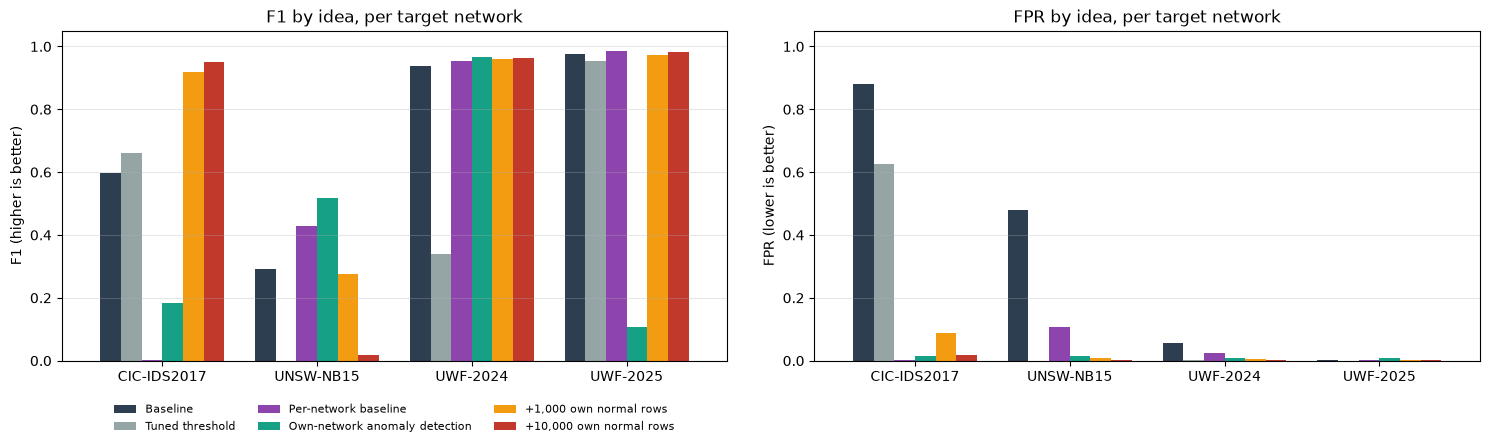

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
colors = ["#2c3e50", "#95a5a6", "#8e44ad", "#16a085", "#f39c12", "#c0392b"]
for ax, metric, ylabel in [(axes[0], "F1", "F1 (higher is better)"), (axes[1], "FPR", "FPR (lower is better)")]:
    t = exp3.pivot(index="Target network", columns="Idea", values=metric)[IDEAS]
    bars(ax, t, f"{metric} by idea, per target network", ylabel, colors)
axes[1].get_legend().remove()
plt.tight_layout()
plt.show()

**ROC curves.** Each curve shows the full trade-off: recall (y) against FPR (x) as the threshold moves. The dot marks the threshold actually used. A curve hugging the top-left is good. The x-axis is logarithmic, because only low FPRs are usable in practice.

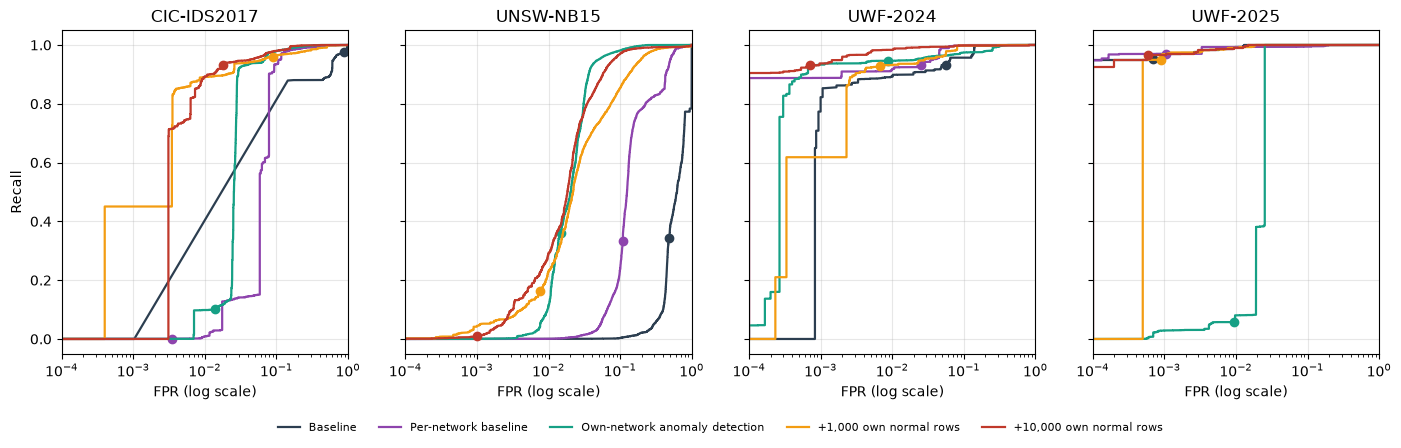

In [11]:
from sklearn.metrics import roc_curve

fig, axes = plt.subplots(1, 4, figsize=(17, 4.2), sharey=True)
for ax, (target, (y, s)) in zip(axes, SCORES.items()):
    for (idea, (sc, thr)), color in zip(s.items(), colors):
        if idea == "Tuned threshold":
            continue  # same scores as the baseline, only the threshold differs
        fpr, tpr, _ = roc_curve(y, sc)
        ax.plot(np.clip(fpr, 1e-4, 1), tpr, color=color, label=idea, lw=1.6)
        flagged = sc >= thr
        ax.plot(max(flagged[y == 0].mean(), 1e-4), flagged[y == 1].mean(), "o", color=color, ms=6)
    ax.set_xscale("log")
    ax.set_xlim(1e-4, 1)
    ax.set_title(target)
    ax.set_xlabel("FPR (log scale)")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Recall")
axes[0].legend(fontsize=8, loc="upper center", bbox_to_anchor=(2.3, -0.18), ncol=5, frameon=False)
plt.tight_layout()
plt.show()

**What it shows**
- **Tuned threshold:** lower FPR, but recall often collapses with it. A threshold set on other networks doesn't fit a new one.
- **Per-network baseline:** it raises ROC-AUC on the hard networks (UNSW-NB15 from 0.35 to 0.82, CIC-IDS2017 from 0.86 to 0.93). But at threshold 0.5 it detects almost nothing on CIC-IDS2017. The ranking improves; the threshold doesn't carry over.
- **Own-network anomaly detection:** ROC-AUC 0.97–0.99 everywhere. At its own threshold (about 1% FPR) it misses most attacks on CIC-IDS2017 and UWF-2025, but the ROC curves show that accepting 1–3% FPR catches about 90% of attacks on every network.
- **Adding the company's normal traffic works on 3 of 4 networks.**
  - CIC-IDS2017: FPR drops from 0.88 to 0.09 (1,000 rows) and 0.02 (10,000 rows), and recall stays above 0.93.
  - UWF-2024 and UWF-2025: FPR 0.007 or less, recall unchanged.
  - **UNSW-NB15: false alarms vanish, but so do the detections** (recall 0.16, then 0.01). The model learns "looks like this network = normal", and UNSW-NB15's attacks look like its own normal traffic to a model trained elsewhere. The ranking is still good (ROC-AUC 0.95–0.97; about 90% recall at 3–5% FPR on the ROC curve), but finding that threshold needs some labelled attacks.
- **10,000 rows vs 1,000:** lower FPR on every network, at the cost of some recall on CIC-IDS2017 and UNSW-NB15.

## What works and what doesn't

| | Finding |
|---|---|
| Doesn't work | **Trusting the evaluation split.** F1 ≈ 0.99 on held-back data from the same datasets says nothing about a new network. |
| Doesn't work | **Training on other labs and deploying as is.** FPR on an unseen network ranges from near 0 to most of its normal traffic. |
| Mixed | **More training datasets.** Training on 1, 3 or 4 datasets helps on some networks and not others; *which* datasets matters more than how many. CIC-IDS2017 alone transfers better than most combinations. |
| Mixed | **Windowing.** Higher recall on unseen datasets, but FPR goes up or down depending on the training data. |
| Unreliable | **Tuned threshold, per-network baseline.** Each helps on one network and fails on another. |
| Promising | **Anomaly detection on the target network's own normal traffic.** No attack labels needed; about 90% recall at 1–3% FPR on every network, if the threshold is set well. |
| Works, mostly | **Adding the target network's normal traffic to training.** 1,000–10,000 normal connections fix the false alarms on every network and keep recall on 3 of 4. On UNSW-NB15 it hides the attacks too. |

**Caveat:** the normal rows come from the same capture as the test blocks (different time periods), so this is a best case. A real network's traffic changes from week to week.

**For CyberShield:** a model trained only on public datasets won't be reliable on a real network. Record a few thousand connections of the protected network's normal traffic and add them to training; that alone fixes most false alarms. Run an anomaly detector on the same normal traffic alongside it as a second opinion, and check both against a few simulated attacks to set the thresholds.